# Catalogue models

The catalogue-level model of Zubeldia et al. (2025) for the 41-tile survey (10% of the sky), as published and
calibrated on map-level simulations. Runs on a laptop CPU in a few minutes.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "retina"
import jax
jax.config.update("jax_enable_x64", True)
from classy_szlite.sim import survey, catalogue as ct, priors, summaries as sm

sz, le, cfg = survey.catalogue_model("published", n_tiles=41)
cells = ct.survey_cells()
th = priors.to_theta(priors.fiducial())
print(f"f_sky = {cfg.f_sky:.4f}")

f_sky = 0.0994


## The noise table

The published model's $q$ is $\bar y_0 / \sigma_{y_0}(\theta_{500})$, with $\sigma_{y_0}$ the matched
filter's noise for the instrument and the CMB: here computed analytically for our filter and the 2019 SO
forecast noise. The paper's own table (for its filter and 40% of the sky) is shown for comparison.

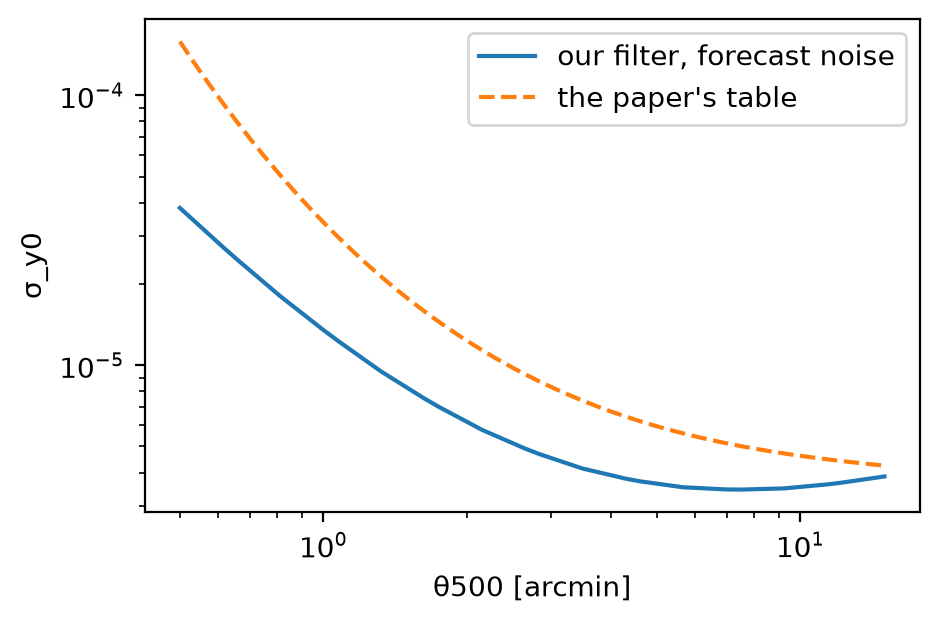

In [2]:
import jax.numpy as jnp
paper_sz, _ = ct.paper_tables()
tt = np.geomspace(0.5, 15, 50)
plt.figure(figsize=(5, 3.2))
plt.loglog(tt, np.asarray(ct.noise_sigma(sz, jnp.asarray(tt))), label="our filter, forecast noise")
plt.loglog(tt, np.asarray(ct.noise_sigma(paper_sz, jnp.asarray(tt))), "--", label="the paper's table")
plt.xlabel("θ500 [arcmin]"); plt.ylabel("σ_y0"); plt.legend()

The two tables belong to different filters and surveys: ours is computed for our filter and the 2019
forecast noise, the paper's for its own set-up. Both fall with the cluster's size, because a larger template
collects more signal against the same noise.

## Expected counts and simulations

`catalogue.expected` integrates the model; `catalogue.simulate` draws catalogues (the halos, their scatter and
noise). The two agree.

In [3]:
ec, en, ep = jax.jit(lambda t: ct.expected(t, cells, sz, le, cfg))(th)
sim = jax.jit(lambda k: ct.simulate(k, th, cells, sz, le, cfg))
t0 = time.time()
cats = [sim(jax.random.key(i)) for i in range(20)]
print(f"20 catalogues in {time.time() - t0:.1f} s (including compilation)")
C = np.array([np.asarray(c.counts) for c in cats])
print("expected counts (rows: q 5-8.4, 8.4-14, 14-24, 24-40; columns: z bins of 0.3):")
print(np.round(np.asarray(ec)).astype(int))
print(f"selected (q > 5): expected {float(en):.0f}, simulated {np.mean([int(c.n_sel) for c in cats]):.0f}; mean p {float(ep / en):.4f}")

20 catalogues in 2.9 s (including compilation)


expected counts (rows: q 5-8.4, 8.4-14, 14-24, 24-40; columns: z bins of 0.3):
[[1267 2930 2515 1488  716]
 [ 560 1230  940  483  200]
 [ 223  468  316  140   49]
 [  74  149   88   33   10]]
selected (q > 5): expected 14570, simulated 14569; mean p 0.2500


The table is the expected number of clusters in each bin of $q$ (rows) and redshift (columns) for 10% of
the sky. Most clusters sit just above the threshold and at intermediate redshift. The simulated catalogues
scatter around the expectation by their Poisson and noise fluctuations.

## Calibrated on map-level simulations

A calibration replaces the instrument-plus-CMB noise by the finder's own noise and, per redshift bin, draws
$q_\mathrm{obs} = \sqrt{(s q)^2 + k} + w\,\mathcal N(0,1)$, with a loss rate $f$. Here the values measured on 20
map-level mocks at the true parameters (the table on the Calibration page), with the finder's noise 7.6% above
the analytic one at 2′ (and the measured ratio at each filter size).

selected: published 14570, calibrated 13993


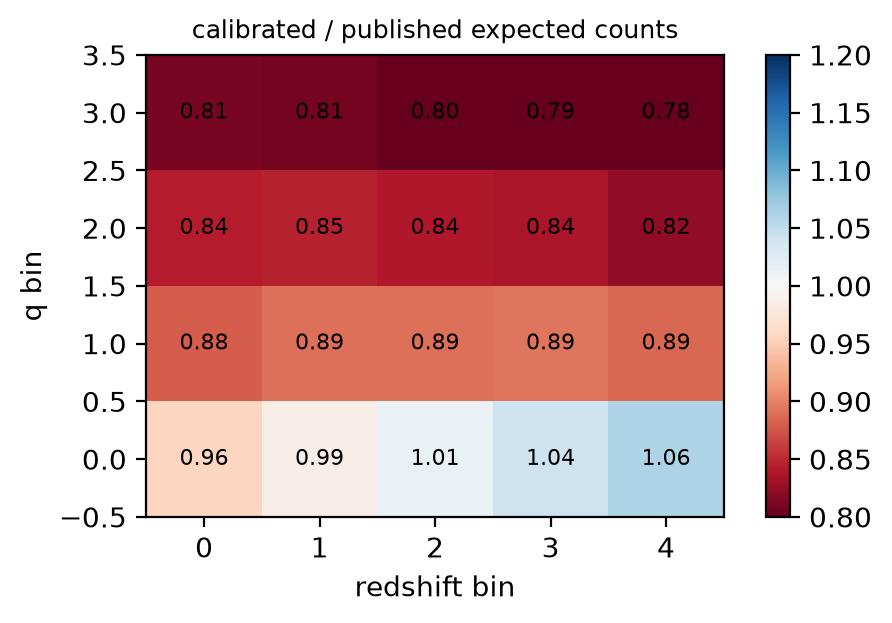

In [4]:
# the finder's noise over the analytic one at the filter's 15 sizes (0.5' to 15'), mean over 41 tiles x 5 mocks
ratio = np.array([1.059, 1.062, 1.064, 1.067, 1.070, 1.073, 1.075, 1.076, 1.076, 1.074, 1.070, 1.064, 1.056, 1.047, 1.038])
sz_cal = sz._replace(lnsig=sz.lnsig + np.log(ratio)[None])
qcal = ((0.31, 0.991, 1.32, 1.035, 0.029), (0.61, 0.989, 1.51, 1.043, 0.013), (0.90, 0.988, 1.50, 1.079, 0.006),
        (1.20, 0.991, 1.29, 1.132, 0.003), (1.50, 0.990, 1.07, 1.177, 0.002), (99.0, 1.002, 0.07, 1.317, 0.0))
cfg_cal = cfg._replace(qcal=qcal)
ec_cal, en_cal, _ = jax.jit(lambda t: ct.expected(t, cells, sz_cal, le, cfg_cal))(th)
r = np.asarray(ec_cal) / np.asarray(ec)
plt.figure(figsize=(5.5, 3))
plt.imshow(r, cmap="RdBu", vmin=0.8, vmax=1.2, origin="lower")
for i in range(4):
    for j in range(5):
        plt.text(j, i, f"{r[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.xlabel("redshift bin"); plt.ylabel("q bin"); plt.title("calibrated / published expected counts", fontsize=9); plt.colorbar()
print(f"selected: published {float(en):.0f}, calibrated {float(en_cal):.0f}")

Calibrated, the model expects 10–25% fewer bright clusters (red cells in the upper rows), because the
finder's noise is higher than the instrument's, and slightly more faint ones at high redshift, because of the
search lift. These are the differences the map-level mocks show against the published model (the Finder
page). The calibrated model reproduces them at the true parameters, but only there.